# Digital Image Processing Lab – Lab Task 04
## Geometric Transformations with Custom Inputs

| | |
|---|---|
| **Name** | YOUR NAME HERE |
| **Roll No.** | 2024-SE-16 |
| **Session / Semester** | 2024-28 (SE) / Fifth |
| **Lab Instructor** | Engr. Fahad Nisar |
| **University / Dept.** | The University of Azad Jammu and Kashmir – Department of Software Engineering |

**Objective:** build one reusable `transform(image, operation, **params)` function that accepts custom values,
validates them, and performs scaling, cropping, flipping, translation and rotation correctly.

## 1. Setup and configuration
All limits are declared once here so that the validation rules are visible and easy to change.

In [1]:
import hashlib
import math
import numbers
import tempfile
import textwrap
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

IMAGE_PATH = Path("Butterfly.jpg")      # input image (kept next to the notebook)
OUTPUT_DIR = Path("output")             # transformed results are saved here
OUTPUT_DIR.mkdir(exist_ok=True)

# ---- declared limits (enforced inside transform) ----
MAX_OUTPUT_SIDE = 8000                  # max width or height of any output, in pixels
MAX_OUTPUT_PIXELS = 40_000_000          # max width * height of any output
MAX_OFFSET = 100_000                    # max |tx| or |ty| for translation, in pixels

# ---- supported choices ----
INTERPOLATIONS = {
    "nearest":  cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic":  cv2.INTER_CUBIC,
    "lanczos":  cv2.INTER_LANCZOS4,
}
FLIP_CODES = {"horizontal": 1, "vertical": 0, "both": -1}   # cv2.flip flip codes

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)
print(f"Limits: side <= {MAX_OUTPUT_SIDE}px, area <= {MAX_OUTPUT_PIXELS:,}px, |offset| <= {MAX_OFFSET:,}px")

OpenCV 5.0.0 | NumPy 2.5.4
Limits: side <= 8000px, area <= 40,000,000px, |offset| <= 100,000px


## 2. Load the image and validate it
`load_image` checks that the file **exists**, **decodes successfully** and has **non-zero dimensions**.
OpenCV decodes to **BGR**, so the image is converted to **RGB once, right here**. From this point on every array in the
notebook is RGB (what Matplotlib expects); the only place that converts back to BGR is `save_result`.
The loaded array is also made **read-only**, so any accidental in-place change to the original raises an error.

File       : Butterfly.jpg
Width      : 1408 px
Height     : 768 px
Array shape: (768, 1408, 3)   (height, width, channels)
dtype      : uint8   | colour order: RGB   | read-only: True


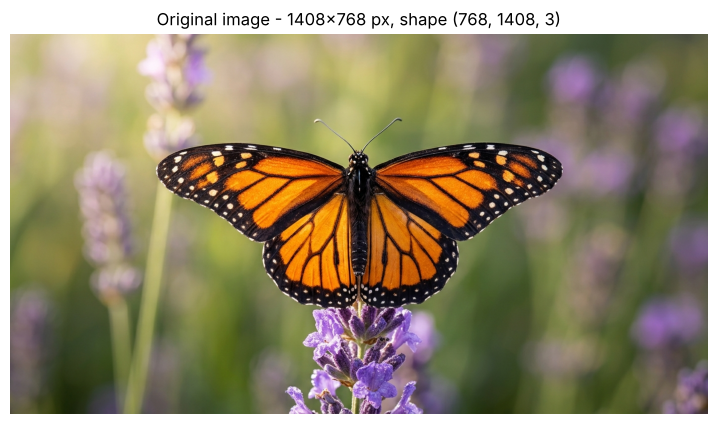

In [2]:
class TransformError(ValueError):
    """Raised for any invalid image, operation name or parameter value."""


def load_image(path):
    """Return the image at *path* as a read-only RGB uint8 array (validated)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Image file not found: {path}")
    if not path.is_file():
        raise ValueError(f"Path is not a file: {path}")
    data = np.fromfile(str(path), dtype=np.uint8)
    if data.size == 0:
        raise ValueError(f"Image file is empty (0 bytes): {path}")
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)          # None if decoding fails
    if bgr is None:
        raise ValueError(f"File could not be decoded as an image: {path}")
    height, width = bgr.shape[:2]
    if height == 0 or width == 0:
        raise ValueError(f"Image has zero size ({width}x{height}): {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)          # single, consistent colour order: RGB
    rgb.flags.writeable = False                         # protect the original
    return rgb


original = load_image(IMAGE_PATH)
ORIGINAL_SHA256 = hashlib.sha256(original.tobytes()).hexdigest()   # used at the end to prove it is unchanged

height, width = original.shape[:2]
print(f"File       : {IMAGE_PATH}")
print(f"Width      : {width} px")
print(f"Height     : {height} px")
print(f"Array shape: {original.shape}   (height, width, channels)")
print(f"dtype      : {original.dtype}   | colour order: RGB   | read-only: {not original.flags.writeable}")

plt.figure(figsize=(9, 5))
plt.imshow(original)
plt.title(f"Original image - {width}x{height} px, shape {original.shape}")
plt.axis("off")
plt.show()

Loader validation: a missing file and a file that is not a real image are both rejected with a clear message.

In [3]:
with tempfile.TemporaryDirectory() as tmp:
    fake = Path(tmp) / "not_an_image.jpg"
    fake.write_text("this is plain text, not JPEG data")
    empty = Path(tmp) / "empty.png"
    empty.write_bytes(b"")
    for label, p in [("missing file", "does_not_exist.jpg"), ("corrupt/non-image file", fake), ("zero-byte file", empty)]:
        try:
            load_image(p)
            print(f"{label}: accepted (unexpected)")
        except (FileNotFoundError, ValueError) as err:
            print(f"[REJECTED] {label}: {err}".replace(tmp, "<tmp>"))

[REJECTED] missing file: Image file not found: does_not_exist.jpg
[REJECTED] corrupt/non-image file: File could not be decoded as an image: <tmp>/not_an_image.jpg
[REJECTED] zero-byte file: Image file is empty (0 bytes): <tmp>/empty.png


## 3. The reusable `transform` function
One entry point: `transform(image, operation, **params)`. It validates **everything itself**, so it is safe to call
directly and not only through the prompts.

| Operation | Required parameters |
|---|---|
| `scale` | `sx`, `sy`, `interpolation` |
| `crop` | `left`, `top`, `right`, `bottom` |
| `flip` | `direction` |
| `translate` | `tx`, `ty` |
| `rotate` | `angle`, `expand` |

Design decisions
* Unknown operations, **missing** parameters and **unexpected** extra parameters are rejected - nothing is silently defaulted.
* Numbers must be real numbers (not strings, not `bool`) and **finite** (NaN / infinity rejected). Zero and negative values are only rejected where they are meaningless (scale factors, crop coordinates).
* Maximum output size is declared in section 1 and checked **before** any large array is allocated.
* **Translation:** `tx > 0` moves the image right, `ty > 0` moves it down. Canvas size is kept; the uncovered area is filled with black.
* **Rotation:** a **positive angle rotates counter-clockwise** (as displayed on screen), about the image centre. `expand=True` enlarges the canvas so nothing is cut off. Angles are reduced modulo 360, so 360 behaves like 0.
* Translation and rotation use bilinear interpolation; scaling uses the interpolation the user chooses.

In [4]:
REQUIRED_PARAMS = {
    "scale":     ("sx", "sy", "interpolation"),
    "crop":      ("left", "top", "right", "bottom"),
    "flip":      ("direction",),
    "translate": ("tx", "ty"),
    "rotate":    ("angle", "expand"),
}


# ------------------------------------------------------------ validation helpers
def _check_image(image):
    if not isinstance(image, np.ndarray):
        raise TransformError(f"image must be a NumPy array, got {type(image).__name__}.")
    if image.dtype != np.uint8:
        raise TransformError(f"image must be uint8, got {image.dtype}.")
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] not in (1, 3, 4)):
        raise TransformError(f"unsupported image shape {image.shape}.")
    if image.shape[0] < 1 or image.shape[1] < 1:
        raise TransformError(f"image has zero size: shape {image.shape}.")


def _real(name, value):
    """Finite real number (bool and str are rejected)."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Real):
        raise TransformError(f"'{name}' must be a number, got {value!r} ({type(value).__name__}).")
    value = float(value)
    if not math.isfinite(value):
        raise TransformError(f"'{name}' must be finite (NaN and infinity are not allowed), got {value}.")
    return value


def _integer(name, value):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Integral):
        raise TransformError(f"'{name}' must be an integer, got {value!r} ({type(value).__name__}).")
    return int(value)


def _choice(name, value, allowed):
    if not isinstance(value, str):
        raise TransformError(f"'{name}' must be text, got {value!r} ({type(value).__name__}).")
    key = value.strip().lower()
    if key not in allowed:
        raise TransformError(f"Unsupported {name} {value!r}. Choose one of: {', '.join(allowed)}.")
    return key


def _check_output_size(out_w, out_h):
    if out_w < 1 or out_h < 1:
        raise TransformError(f"Output would be {out_w}x{out_h} px - an empty image is not allowed (minimum 1x1).")
    if out_w > MAX_OUTPUT_SIDE or out_h > MAX_OUTPUT_SIDE:
        raise TransformError(f"Output {out_w}x{out_h} px exceeds the maximum side length of {MAX_OUTPUT_SIDE} px.")
    if out_w * out_h > MAX_OUTPUT_PIXELS:
        raise TransformError(f"Output {out_w}x{out_h} px exceeds the maximum area of {MAX_OUTPUT_PIXELS:,} pixels.")


# ------------------------------------------------------------ the five operations
def _scale(image, sx, sy, interpolation):
    sx, sy = _real("sx", sx), _real("sy", sy)
    if sx <= 0 or sy <= 0:
        raise TransformError(f"Scale factors must be greater than zero, got sx={sx}, sy={sy}.")
    method = _choice("interpolation", interpolation, INTERPOLATIONS)
    h, w = image.shape[:2]
    out_w, out_h = math.floor(w * sx + 0.5), math.floor(h * sy + 0.5)   # round half up
    _check_output_size(out_w, out_h)
    return cv2.resize(image, (out_w, out_h), interpolation=INTERPOLATIONS[method])


def _crop(image, left, top, right, bottom):
    left, top = _integer("left", left), _integer("top", top)
    right, bottom = _integer("right", right), _integer("bottom", bottom)
    h, w = image.shape[:2]
    if not (0 <= left < right <= w):
        raise TransformError(f"Invalid horizontal range: need 0 <= left < right <= width ({w}); got left={left}, right={right}.")
    if not (0 <= top < bottom <= h):
        raise TransformError(f"Invalid vertical range: need 0 <= top < bottom <= height ({h}); got top={top}, bottom={bottom}.")
    return image[top:bottom, left:right].copy()          # right/bottom exclusive; copy so it is independent


def _flip(image, direction):
    direction = _choice("direction", direction, FLIP_CODES)
    return cv2.flip(image, FLIP_CODES[direction])


def _translate(image, tx, ty):
    tx, ty = _real("tx", tx), _real("ty", ty)
    if abs(tx) > MAX_OFFSET or abs(ty) > MAX_OFFSET:
        raise TransformError(f"Offsets must satisfy |tx|, |ty| <= {MAX_OFFSET:,}; got tx={tx}, ty={ty}.")
    h, w = image.shape[:2]
    M = np.array([[1.0, 0.0, tx],
                  [0.0, 1.0, ty]])                        # affine matrix for a pure shift
    return cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)


def _rotate(image, angle, expand):
    angle = _real("angle", angle)
    if not isinstance(expand, (bool, np.bool_)):
        raise TransformError(f"'expand' must be True or False, got {expand!r} ({type(expand).__name__}).")
    h, w = image.shape[:2]
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0                 # centre of the image (pixel-centre convention)
    M = cv2.getRotationMatrix2D((cx, cy), angle % 360.0, 1.0)   # positive angle = counter-clockwise
    out_w, out_h = w, h
    if expand:
        c, s = abs(M[0, 0]), abs(M[0, 1])
        out_w = math.ceil(round(h * s + w * c, 6))        # round() first: avoids 1409 caused by 1e-13 noise
        out_h = math.ceil(round(h * c + w * s, 6))
        _check_output_size(out_w, out_h)
        M[0, 2] += (out_w - 1) / 2.0 - cx                 # move the old centre to the new canvas centre
        M[1, 2] += (out_h - 1) / 2.0 - cy
    return cv2.warpAffine(image, M, (out_w, out_h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)


_HANDLERS = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}


# ------------------------------------------------------------ the single entry point
def transform(image, operation, **params):
    """Apply one geometric *operation* to *image* using the custom *params*; return the new image."""
    _check_image(image)
    if not isinstance(operation, str) or not operation.strip():
        raise TransformError("operation must be a non-empty string.")
    op = operation.strip().lower()
    if op not in REQUIRED_PARAMS:
        raise TransformError(f"Unknown operation {operation!r}. Supported: {', '.join(REQUIRED_PARAMS)}.")
    required = REQUIRED_PARAMS[op]
    missing = [p for p in required if params.get(p) is None]
    if missing:
        raise TransformError(f"Operation '{op}' is missing required parameter(s): {', '.join(missing)}.")
    extra = [p for p in params if p not in required]
    if extra:
        raise TransformError(f"Operation '{op}' got unexpected parameter(s): {', '.join(extra)}. Expected: {', '.join(required)}.")
    return _HANDLERS[op](image, **params)


# quick smoke test
print("transform() ready. Quick test:", transform(original, "flip", direction="horizontal").shape)

transform() ready. Quick test: (768, 1408, 3)


## 4. User input: prompts, text parsing and error handling
Everything a user types arrives as **text**. `parse_value` converts it (rejecting non-numeric text), then the converted
values are passed to `transform`, which validates them again. Errors are printed as clear messages and the user can
correct the input - the notebook never crashes.

* `interactive_session()` is the notebook prompt loop (uses `input()`): choose an operation, enter its parameters, see the result.
* `safe_run()` wraps text input -> `transform` -> error message.

In [5]:
# (name, kind, prompt text) for every operation - drives the prompts
PARAM_SPECS = {
    "scale":     [("sx", "float", "Horizontal scale factor sx (> 0)"),
                  ("sy", "float", "Vertical scale factor sy (> 0)"),
                  ("interpolation", "text", "Interpolation (nearest / bilinear / bicubic / lanczos)")],
    "crop":      [("left", "int", "Left (x, inclusive)"),
                  ("top", "int", "Top (y, inclusive)"),
                  ("right", "int", "Right (x, exclusive)"),
                  ("bottom", "int", "Bottom (y, exclusive)")],
    "flip":      [("direction", "text", "Direction (horizontal / vertical / both)")],
    "translate": [("tx", "float", "Horizontal offset tx in pixels (+ right, - left)"),
                  ("ty", "float", "Vertical offset ty in pixels (+ down, - up)")],
    "rotate":    [("angle", "float", "Angle in degrees (+ = counter-clockwise)"),
                  ("expand", "bool", "Expand canvas to fit the whole rotated image? (yes / no)")],
}


def parse_value(name, kind, text):
    """Convert typed text to a Python value; raise TransformError with a clear message if impossible."""
    text = "" if text is None else str(text).strip()
    if text == "":
        raise TransformError(f"'{name}' is missing - please enter a value.")
    if kind == "float":
        try:
            return float(text)            # 'nan' and 'inf' parse fine here; transform() rejects them
        except ValueError:
            raise TransformError(f"'{name}' must be a number, but {text!r} is not numeric.") from None
    if kind == "int":
        try:
            return int(text)
        except ValueError:
            raise TransformError(f"'{name}' must be a whole number, but {text!r} is not.") from None
    if kind == "bool":
        t = text.lower()
        if t in ("yes", "y", "true", "t", "1"):
            return True
        if t in ("no", "n", "false", "f", "0"):
            return False
        raise TransformError(f"'{name}' must be yes or no, got {text!r}.")
    return text                           # kind == "text": transform() checks the allowed choices


def build_request(op_text, raw):
    """operation text + dict of typed strings  ->  (operation, parsed params)."""
    op = op_text.strip().lower() if isinstance(op_text, str) else ""
    if op not in PARAM_SPECS:
        raise TransformError(f"Unknown operation {op_text!r}. Supported: {', '.join(PARAM_SPECS)}.")
    return op, {name: parse_value(name, kind, raw.get(name)) for name, kind, _ in PARAM_SPECS[op]}


def run_from_text(image, op_text, raw):
    op, params = build_request(op_text, raw)
    return transform(image, op, **params), op, params


def safe_run(image, op_text, raw, verbose=True):
    """Run from text input. Returns (result, op, params) or None after printing a clear error."""
    try:
        return run_from_text(image, op_text, raw)
    except TransformError as err:
        if verbose:
            print(f"[REJECTED] {err}")
    except Exception as err:                                  # safety net: never crash the notebook
        if verbose:
            print(f"[ERROR] unexpected {type(err).__name__}: {err}")
    return None


# ------------------------------------------------------------ display / save helpers
def fmt_params(params):
    return ", ".join(f"{k}={v}" for k, v in params.items())


def save_result(stem, image):
    """Save an RGB result as a lossless PNG in OUTPUT_DIR (converted to BGR only for cv2.imwrite)."""
    path = OUTPUT_DIR / f"{stem}.png"
    if not cv2.imwrite(str(path), cv2.cvtColor(image, cv2.COLOR_RGB2BGR)):
        raise IOError(f"could not write {path}")
    return path


def show_gallery(items, ncols=None, true_scale=False, figwidth=15):
    """items = [(title, image), ...]. true_scale=True draws one row with widths proportional to pixel widths."""
    n = len(items)
    if true_scale:
        widths = [im.shape[1] for _, im in items]
        fig = plt.figure(figsize=(figwidth, figwidth * max(im.shape[0] for _, im in items) / sum(widths) + 0.9))
        grid = fig.add_gridspec(1, n, width_ratios=widths)
        axes = [fig.add_subplot(grid[0, i]) for i in range(n)]
    else:
        ncols = ncols or min(n, 3)
        nrows = math.ceil(n / ncols)
        fig, axs = plt.subplots(nrows, ncols, figsize=(figwidth, figwidth / ncols * 0.62 * nrows + 0.5))
        axes = list(np.atleast_1d(axs).ravel())
    for ax, (title, im) in zip(axes, items):
        ax.imshow(im)
        ax.axis("off")
        wrap = 26 if true_scale and im.shape[1] < 900 else 44
        ax.set_title(textwrap.fill(title, wrap) if true_scale else title, fontsize=9)
    for ax in axes[n:]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()


def title_for(op, params, result):
    return f"{op}({fmt_params(params)})\nOutput: {result.shape[1]}x{result.shape[0]} px"


original_title = f"Original\n{width}x{height} px"
RESULTS_LOG = []        # collects every saved demo result for the summary table


def run_cases(op, cases):
    """cases = [(file_stem, params), ...]. Runs transform for each, saves PNGs, logs them, returns gallery items."""
    items = []
    for stem, params in cases:
        result = transform(original, op, **params)            # direct call with custom values
        path = save_result(stem, result)
        RESULTS_LOG.append({"Operation": op, "Parameters": fmt_params(params),
                            "Output size (WxH)": f"{result.shape[1]}x{result.shape[0]}", "Saved file": str(path)})
        print(f"[OK] {op}({fmt_params(params)}) -> {result.shape[1]}x{result.shape[0]} px   saved: {path}")
        items.append((title_for(op, params, result), result))
    return items

In [6]:
def interactive_session(image, input_fn=input, show=True, save_prefix="interactive"):
    """Prompt loop: choose an operation, type its parameters, get the result. Type q at any prompt to quit."""
    class _Quit(Exception):
        pass

    def ask(prompt):
        answer = input_fn(prompt)
        if answer.strip().lower() in ("q", "quit", "exit"):
            raise _Quit
        return answer

    saved, count = [], 0
    try:
        while True:
            op = ask(f"Operation ({' / '.join(PARAM_SPECS)}) or q to quit: ").strip().lower()
            if op not in PARAM_SPECS:
                print(f"[REJECTED] Unknown operation {op!r}. Choose one of: {', '.join(PARAM_SPECS)}.")
                continue
            while True:                                        # retry loop: lets the user correct the values
                raw = {}
                for name, kind, prompt in PARAM_SPECS[op]:
                    while True:                                # field-level correction
                        text = ask(f"  {prompt}: ")
                        try:
                            parse_value(name, kind, text)
                            raw[name] = text
                            break
                        except TransformError as err:
                            print(f"  [REJECTED] {err}  -> try again")
                outcome = safe_run(image, op, raw)
                if outcome is not None:
                    break
                print("  Please re-enter the values for this operation.")
            result, op, params = outcome
            count += 1
            saved.append(save_result(f"{save_prefix}_{count}_{op}", result))
            print(f"[OK] {op}({fmt_params(params)}) -> {result.shape[1]}x{result.shape[0]} px, saved {saved[-1]}")
            if show:
                show_gallery([(original_title, image), (title_for(op, params, result), result)], ncols=2, figwidth=11)
    except _Quit:
        print("Session ended.")
    return saved

### Using the prompts yourself
Set `RUN_INTERACTIVE = True` and run the next cell to type your own operation and parameters.
It is `False` by default so that **Restart & Run All** finishes without waiting for the keyboard.

In [7]:
RUN_INTERACTIVE = False      # <- change to True to be prompted for your own values

if RUN_INTERACTIVE:
    interactive_session(original)
else:
    print("Interactive prompts are off. Set RUN_INTERACTIVE = True and re-run this cell to use them.")

Interactive prompts are off. Set RUN_INTERACTIVE = True and re-run this cell to use them.


### Demonstration of the prompt loop with typed answers
To show the prompt loop in the saved output, the next cell **feeds scripted answers** into the same
`interactive_session` function (each line below is exactly what a user would type after the prompt).
It deliberately includes mistakes - non-numeric text, an invalid crop box, an invalid yes/no and an unsupported flip direction -
so you can see the error messages and the correction.

Operation (scale / crop / flip / translate / rotate) or q to quit: scale
  Horizontal scale factor sx (> 0): abc
  [REJECTED] 'sx' must be a number, but 'abc' is not numeric.  -> try again
  Horizontal scale factor sx (> 0): 1.5
  Vertical scale factor sy (> 0): 0.75
  Interpolation (nearest / bilinear / bicubic / lanczos): lanczos
[OK] scale(sx=1.5, sy=0.75, interpolation=lanczos) -> 2112x576 px, saved output/interactive_1_scale.png


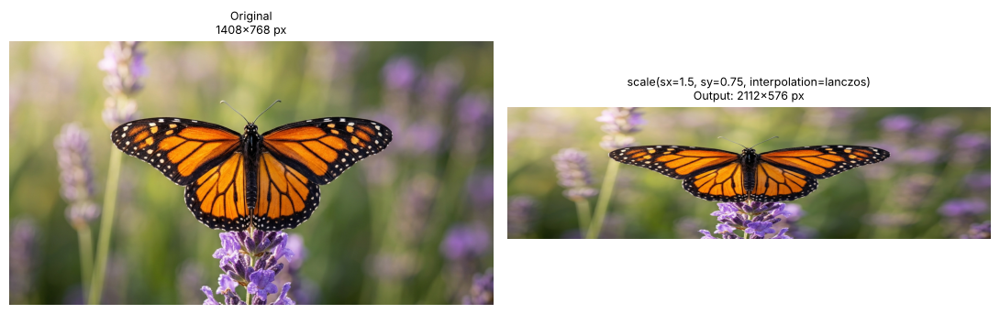

Operation (scale / crop / flip / translate / rotate) or q to quit: crop
  Left (x, inclusive): 500
  Top (y, inclusive): 100
  Right (x, exclusive): 400
  Bottom (y, exclusive): 300
[REJECTED] Invalid horizontal range: need 0 <= left < right <= width (1408); got left=500, right=400.
  Please re-enter the values for this operation.
  Left (x, inclusive): 400
  Top (y, inclusive): 60
  Right (x, exclusive): 1000
  Bottom (y, exclusive): 520
[OK] crop(left=400, top=60, right=1000, bottom=520) -> 600x460 px, saved output/interactive_2_crop.png


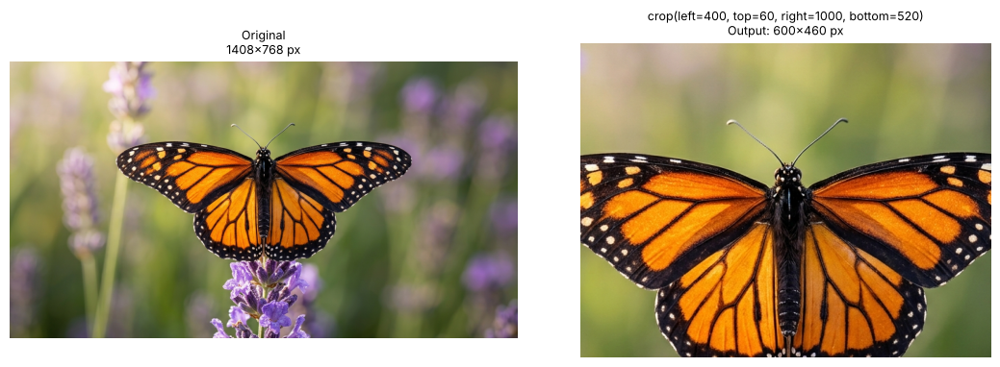

Operation (scale / crop / flip / translate / rotate) or q to quit: rotate
  Angle in degrees (+ = counter-clockwise): -30
  Expand canvas to fit the whole rotated image? (yes / no): maybe
  [REJECTED] 'expand' must be yes or no, got 'maybe'.  -> try again
  Expand canvas to fit the whole rotated image? (yes / no): yes
[OK] rotate(angle=-30.0, expand=True) -> 1604x1370 px, saved output/interactive_3_rotate.png


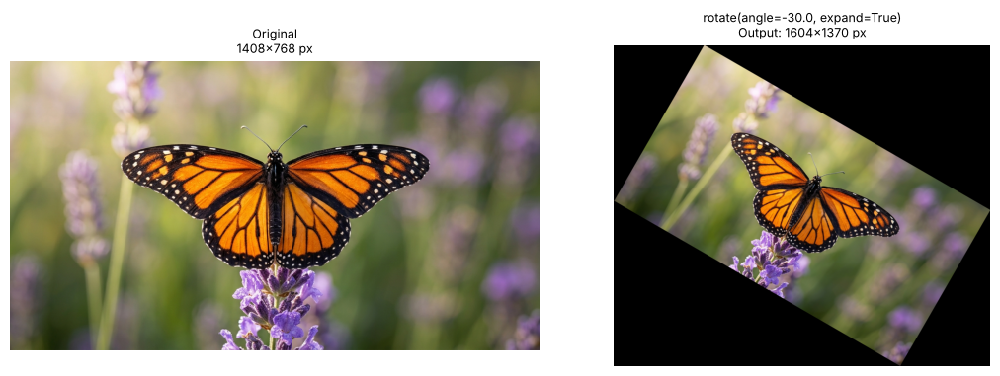

Operation (scale / crop / flip / translate / rotate) or q to quit: flip
  Direction (horizontal / vertical / both): diagonal
[REJECTED] Unsupported direction 'diagonal'. Choose one of: horizontal, vertical, both.
  Please re-enter the values for this operation.
  Direction (horizontal / vertical / both): both
[OK] flip(direction=both) -> 1408x768 px, saved output/interactive_4_flip.png


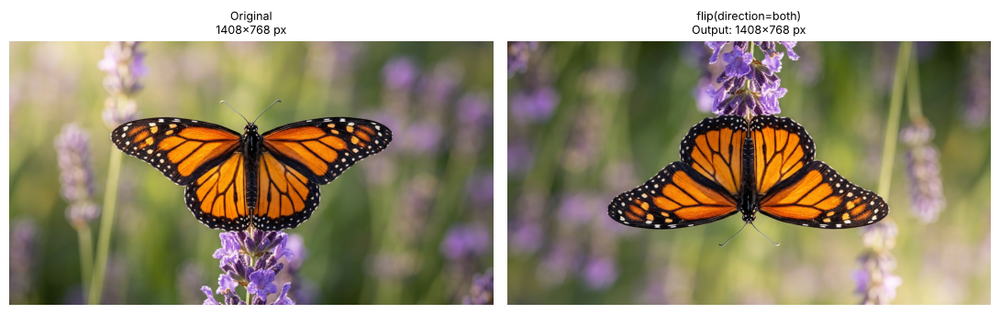

Operation (scale / crop / flip / translate / rotate) or q to quit: translate
  Horizontal offset tx in pixels (+ right, - left): 120
  Vertical offset ty in pixels (+ down, - up): -40
[OK] translate(tx=120.0, ty=-40.0) -> 1408x768 px, saved output/interactive_5_translate.png


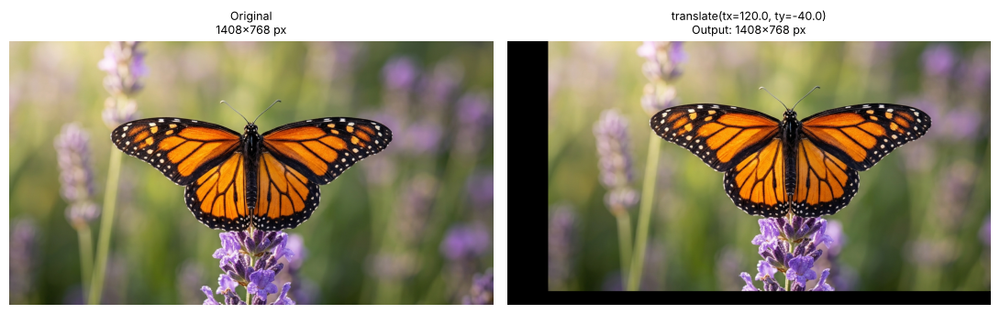

Operation (scale / crop / flip / translate / rotate) or q to quit: q
Session ended.


In [8]:
def scripted_input(answers):
    """Return an input()-like function that replays *answers* and echoes them like a real prompt."""
    it = iter(answers)

    def _input(prompt=""):
        answer = next(it)
        print(f"{prompt}{answer}")
        return answer
    return _input


typed_answers = [
    "scale",     "abc", "1.5", "0.75", "lanczos",          # 'abc' is not a number -> re-asked
    "crop",      "500", "100", "400", "300",               # left >= right -> rejected, values re-entered
                 "400", "60", "1000", "520",
    "rotate",    "-30", "maybe", "yes",                    # 'maybe' is not yes/no -> re-asked
    "flip",      "diagonal",                               # unsupported direction -> rejected
                 "both",
    "translate", "120", "-40",
    "q",
]
saved_interactive = interactive_session(original, input_fn=scripted_input(typed_answers))

## 5. Demonstration of every operation (custom values)
Each figure shows the **original on the left** and the transformed result(s) with a label giving the **operation, parameters
and output dimensions**. Every result is saved to the `output/` folder.

### 5.1 Scaling / resizing
Output size = `round(width * sx)` x `round(height * sy)`. Below: a proportional **enlargement** (2x), a proportional
**reduction** (0.4x), and two **non-proportional** scalings. The first figure is drawn at true relative scale.

[OK] scale(sx=2.0, sy=2.0, interpolation=bicubic) -> 2816x1536 px   saved: output/scale_enlarge_2.0x2.0_bicubic.png
[OK] scale(sx=0.4, sy=0.4, interpolation=bilinear) -> 563x307 px   saved: output/scale_reduce_0.4x0.4_bilinear.png


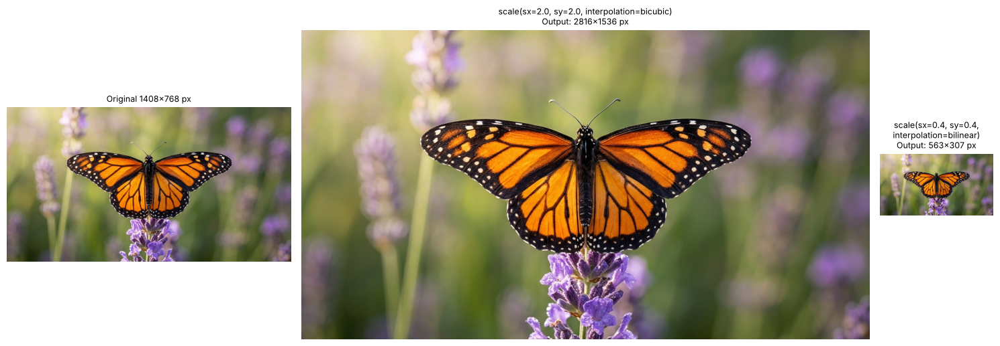

In [9]:
prop_items = run_cases("scale", [
    ("scale_enlarge_2.0x2.0_bicubic",  dict(sx=2.0, sy=2.0, interpolation="bicubic")),    # enlargement
    ("scale_reduce_0.4x0.4_bilinear",  dict(sx=0.4, sy=0.4, interpolation="bilinear")),   # reduction
])
show_gallery([(original_title, original)] + prop_items, true_scale=True)

[OK] scale(sx=1.5, sy=0.6, interpolation=lanczos) -> 2112x461 px   saved: output/scale_nonprop_1.5x0.6_lanczos.png
[OK] scale(sx=0.5, sy=1.5, interpolation=bilinear) -> 704x1152 px   saved: output/scale_nonprop_0.5x1.5_bilinear.png


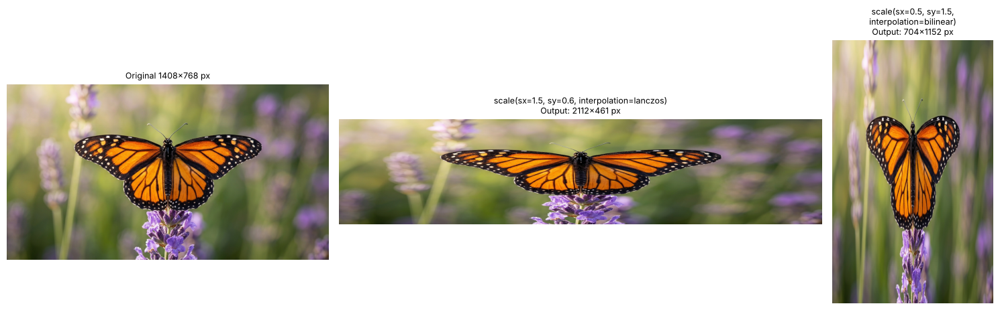

,Case,Width,Height,sx / sy,Aspect ratio (W/H),Distorted?
0,original,1408,768,1.000000,1.833,no
1,"sx=2.0, sy=2.0",2816,1536,1.000000,1.833,no
2,"sx=0.4, sy=0.4",563,307,1.000000,1.834,no
3,"sx=1.5, sy=0.6",2112,461,2.500000,4.581,YES
4,"sx=0.5, sy=1.5",704,1152,0.333333,0.611,YES


In [10]:
nonprop_items = run_cases("scale", [
    ("scale_nonprop_1.5x0.6_lanczos",  dict(sx=1.5, sy=0.6, interpolation="lanczos")),    # wide and squashed
    ("scale_nonprop_0.5x1.5_bilinear", dict(sx=0.5, sy=1.5, interpolation="bilinear")),   # narrow and stretched
])
show_gallery([(original_title, original)] + nonprop_items, true_scale=True)

# aspect-ratio table
rows = [("original", width, height, 1.0)]
for (title, im), (sx, sy) in zip(prop_items + nonprop_items, [(2.0, 2.0), (0.4, 0.4), (1.5, 0.6), (0.5, 1.5)]):
    rows.append((f"sx={sx}, sy={sy}", im.shape[1], im.shape[0], sx / sy))
aspect = pd.DataFrame(rows, columns=["Case", "Width", "Height", "sx / sy"])
aspect["Aspect ratio (W/H)"] = (aspect["Width"] / aspect["Height"]).round(3)
aspect["Distorted?"] = np.where(np.isclose(aspect["Aspect ratio (W/H)"], width / height, atol=0.005), "no", "YES")
display(aspect)

**Observations.** With `sx == sy` the aspect ratio (1.833) is unchanged - the butterfly is only larger or smaller.
When `sx != sy` the ratio changes by the factor `sx / sy`: at 1.5 x 0.6 the butterfly looks wide and flattened, at 0.5 x 1.5 it looks tall and
narrow. Rounding to whole pixels can shift the ratio in the third decimal place, which is why the table is compared with a small tolerance.

### 5.2 Cropping
Coordinates are **(x, y)** with the origin at the top-left. `left` and `top` are inclusive, `right` and `bottom` are **exclusive**,
so the output size is exactly `(right - left) x (bottom - top)`.

[OK] crop(left=400, top=60, right=1000, bottom=520) -> 600x460 px   saved: output/crop_body_400_60_1000_520.png
[OK] crop(left=0, top=0, right=704, bottom=384) -> 704x384 px   saved: output/crop_topleft_0_0_704_384.png
Size check passed: output = (right-left) x (bottom-top).


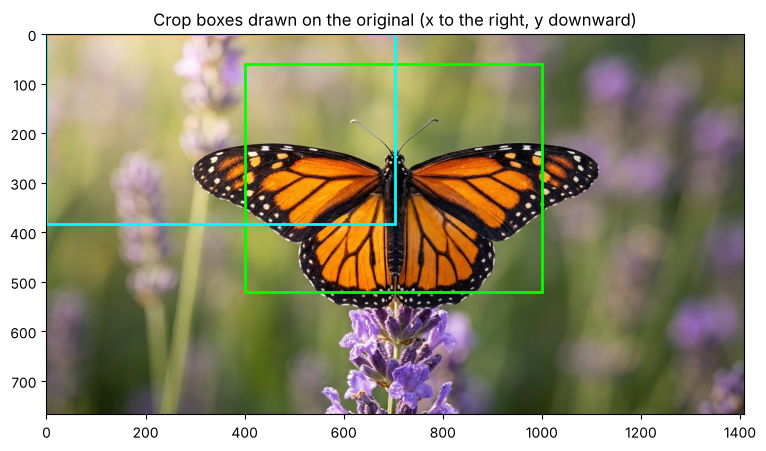

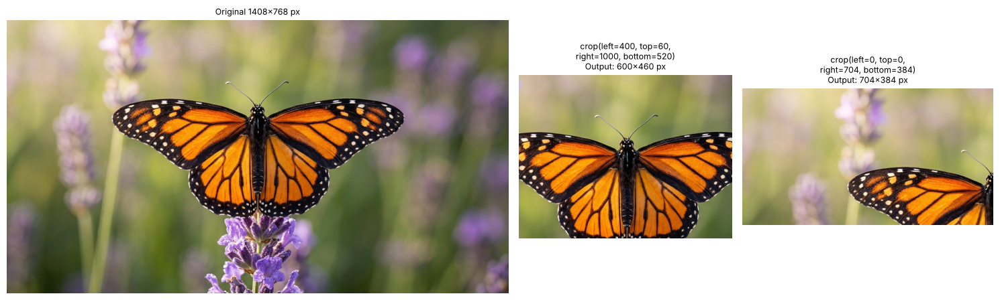

In [11]:
crop_boxes = [
    ("crop_body_400_60_1000_520",       dict(left=400, top=60,  right=1000, bottom=520)),   # butterfly body
    ("crop_topleft_0_0_704_384",        dict(left=0,   top=0,   right=704,  bottom=384)),   # top-left quarter
]
crop_items = run_cases("crop", crop_boxes)

# Right/bottom are exclusive: output size must equal (right-left) x (bottom-top)
for (_, p), (_, im) in zip(crop_boxes, crop_items):
    assert im.shape[:2] == (p["bottom"] - p["top"], p["right"] - p["left"])
print("Size check passed: output = (right-left) x (bottom-top).")

# show the crop boxes on the original
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(original)
for (_, p), colour in zip(crop_boxes, ["lime", "cyan"]):
    ax.add_patch(Rectangle((p["left"], p["top"]), p["right"] - p["left"], p["bottom"] - p["top"],
                           fill=False, edgecolor=colour, linewidth=2))
ax.set_title("Crop boxes drawn on the original (x to the right, y downward)")
plt.show()
show_gallery([(original_title, original)] + crop_items, true_scale=True)

**Observations.** Cropping only selects a rectangle of existing pixels - no pixel values change and nothing is resampled.
The saved crop is a copy, so editing it can never alter the original.

### 5.3 Flipping
`horizontal` mirrors left-right, `vertical` mirrors top-bottom, `both` does both (equivalent to a 180 degree rotation).

[OK] flip(direction=horizontal) -> 1408x768 px   saved: output/flip_horizontal.png
[OK] flip(direction=vertical) -> 1408x768 px   saved: output/flip_vertical.png
[OK] flip(direction=both) -> 1408x768 px   saved: output/flip_both.png


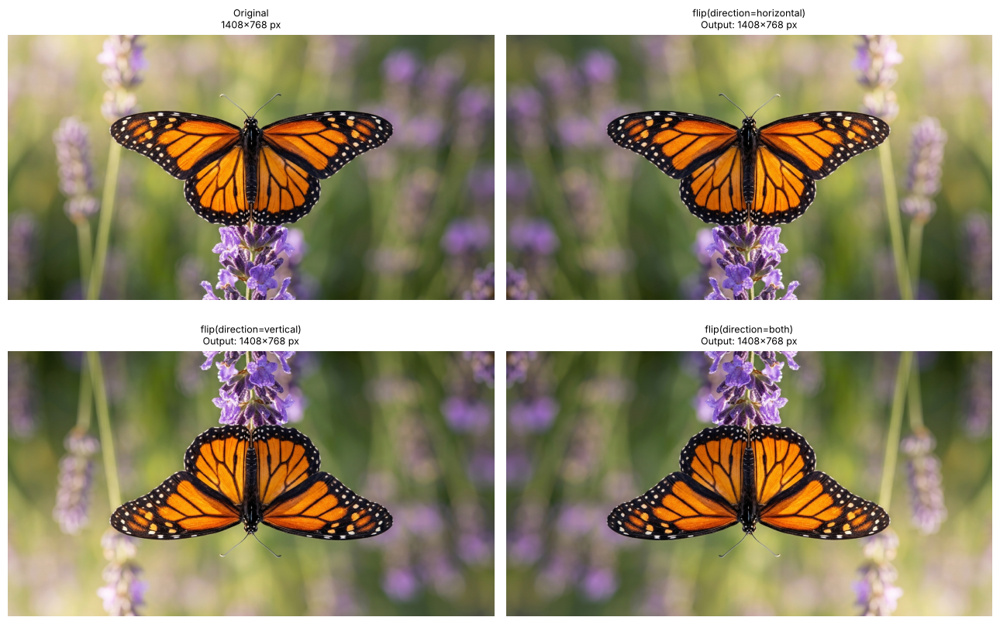

In [12]:
flip_items = run_cases("flip", [
    ("flip_horizontal", dict(direction="horizontal")),
    ("flip_vertical",   dict(direction="vertical")),
    ("flip_both",       dict(direction="both")),
])
show_gallery([(original_title, original)] + flip_items, ncols=2, figwidth=13)

**Observations.** The output size never changes for flips. Horizontal flip swaps the left and right wings, vertical flip puts the
flower above the butterfly, and `both` gives an upside-down mirror image.

### 5.4 Translation
`tx > 0` shifts right, `tx < 0` left; `ty > 0` shifts down, `ty < 0` up. The **canvas size is kept**, so pixels pushed outside are **clipped (lost)**
and the exposed strip is filled with black.

[OK] translate(tx=200, ty=80) -> 1408x768 px   saved: output/translate_tx+200_ty+80.png
[OK] translate(tx=-150, ty=-60) -> 1408x768 px   saved: output/translate_tx-150_ty-60.png


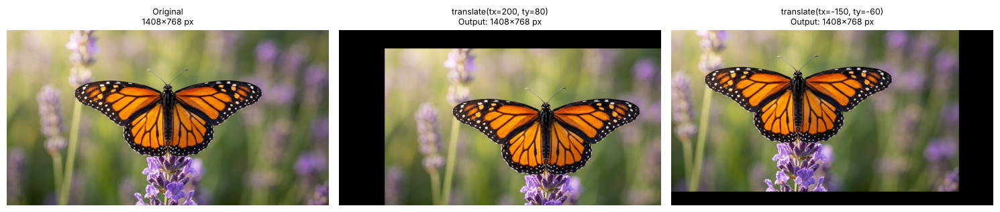

,tx,ty,Output size,Pixels clipped (= exposed black),% of canvas
0,200,80,1408x768,250240,23.1
1,-150,-60,1408x768,190680,17.6


In [13]:
translate_items = run_cases("translate", [
    ("translate_tx+200_ty+80",  dict(tx=200, ty=80)),      # right and down
    ("translate_tx-150_ty-60",  dict(tx=-150, ty=-60)),    # left and up (opposite direction)
])
show_gallery([(original_title, original)] + translate_items, ncols=3, figwidth=15)

# how many pixels are clipped / exposed
rows = []
for tx, ty in [(200, 80), (-150, -60)]:
    kept = max(0, width - abs(tx)) * max(0, height - abs(ty))
    lost = width * height - kept
    rows.append({"tx": tx, "ty": ty, "Output size": f"{width}x{height}",
                 "Pixels clipped (= exposed black)": lost, "% of canvas": round(100 * lost / (width * height), 1)})
display(pd.DataFrame(rows))

**Observations.** Moving the image right/down exposes black bands on the **left and top**; moving it left/up exposes them on the **right and bottom**.
The same number of pixels leave the canvas as are uncovered, and they cannot be recovered by moving back (shown in section 9).

### 5.5 Rotation
The angle is in degrees; a **positive angle rotates counter-clockwise**, a negative angle clockwise, about the image centre.
`expand=False` keeps the original canvas (corners are cut off); `expand=True` grows the canvas so the whole image fits.

[OK] rotate(angle=30, expand=False) -> 1408x768 px   saved: output/rotate_+30_noexpand.png
[OK] rotate(angle=30, expand=True) -> 1604x1370 px   saved: output/rotate_+30_expand.png
[OK] rotate(angle=-45, expand=True) -> 1539x1539 px   saved: output/rotate_-45_expand.png
[OK] rotate(angle=-20, expand=False) -> 1408x768 px   saved: output/rotate_-20_noexpand.png


[OK] rotate(angle=90, expand=True) -> 768x1408 px   saved: output/rotate_90_expand.png


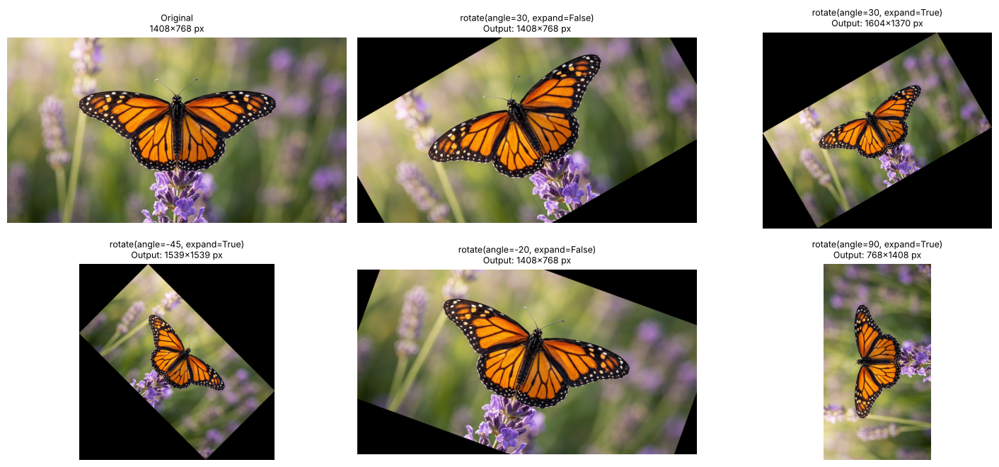

,Angle,Formula W' x H',Actual (ceil),Match
0,30,1603.36 x 1369.11,1604 x 1370,True
1,-45,1538.66 x 1538.66,1539 x 1539,True
2,90,768.00 x 1408.00,768 x 1408,True


In [14]:
rotate_items = run_cases("rotate", [
    ("rotate_+30_noexpand",  dict(angle=30,  expand=False)),
    ("rotate_+30_expand",    dict(angle=30,  expand=True)),
    ("rotate_-45_expand",    dict(angle=-45, expand=True)),
    ("rotate_-20_noexpand",  dict(angle=-20, expand=False)),
    ("rotate_90_expand",     dict(angle=90,  expand=True)),
])
show_gallery([(original_title, original)] + rotate_items, ncols=3, figwidth=15)

# check the expanded canvas against the formula  W' = w|cos| + h|sin| ,  H' = w|sin| + h|cos|
rows = []
for (stem, p), (_, im) in zip([("", dict(angle=30, expand=True)), ("", dict(angle=-45, expand=True)), ("", dict(angle=90, expand=True))],
                              [rotate_items[1], rotate_items[2], rotate_items[4]]):
    t = math.radians(abs(p["angle"]))
    exp_w = width * abs(math.cos(t)) + height * abs(math.sin(t))
    exp_h = width * abs(math.sin(t)) + height * abs(math.cos(t))
    rows.append({"Angle": p["angle"], "Formula W' x H'": f"{exp_w:.2f} x {exp_h:.2f}",
                 "Actual (ceil)": f"{im.shape[1]} x {im.shape[0]}",
                 "Match": im.shape[1] == math.ceil(round(exp_w, 6)) and im.shape[0] == math.ceil(round(exp_h, 6))})
display(pd.DataFrame(rows))

**Observations.** +30 turns the butterfly counter-clockwise, -45 and -20 turn it clockwise. Without expansion the corners
of the picture are cut off and black triangles appear; with expansion nothing is lost but the canvas grows (1408x768 becomes a larger
canvas, and a 90 degree rotation simply swaps width and height to 768x1408).

### 5.6 Summary of everything saved by the demonstrations

In [15]:
display(pd.DataFrame(RESULTS_LOG))

,Operation,Parameters,Output size (WxH),Saved file
0,scale,"sx=2.0, sy=2.0, interpolation=bicubic",2816x1536,output/scale_enlarge_2.0x2.0_bicubic.png
1,scale,"sx=0.4, sy=0.4, interpolation=bilinear",563x307,output/scale_reduce_0.4x0.4_bilinear.png
2,scale,"sx=1.5, sy=0.6, interpolation=lanczos",2112x461,output/scale_nonprop_1.5x0.6_lanczos.png
3,scale,"sx=0.5, sy=1.5, interpolation=bilinear",704x1152,output/scale_nonprop_0.5x1.5_bilinear.png
4,crop,"left=400, top=60, right=1000, bottom=520",600x460,output/crop_body_400_60_1000_520.png
5,crop,"left=0, top=0, right=704, bottom=384",704x384,output/crop_topleft_0_0_704_384.png
6,flip,direction=horizontal,1408x768,output/flip_horizontal.png
7,flip,direction=vertical,1408x768,output/flip_vertical.png
8,flip,direction=both,1408x768,output/flip_both.png
9,translate,"tx=200, ty=80",1408x768,output/translate_tx+200_ty+80.png


## 6. Interpolation comparison on one enlarged patch
A small 50x37 px patch (white spots, an orange spot and sharp black/orange edges) is cut out with `transform(..., "crop")` and then enlarged
**8x** with each of the four interpolation methods, using `transform(..., "scale")`.

Source patch: 50 x 37 px


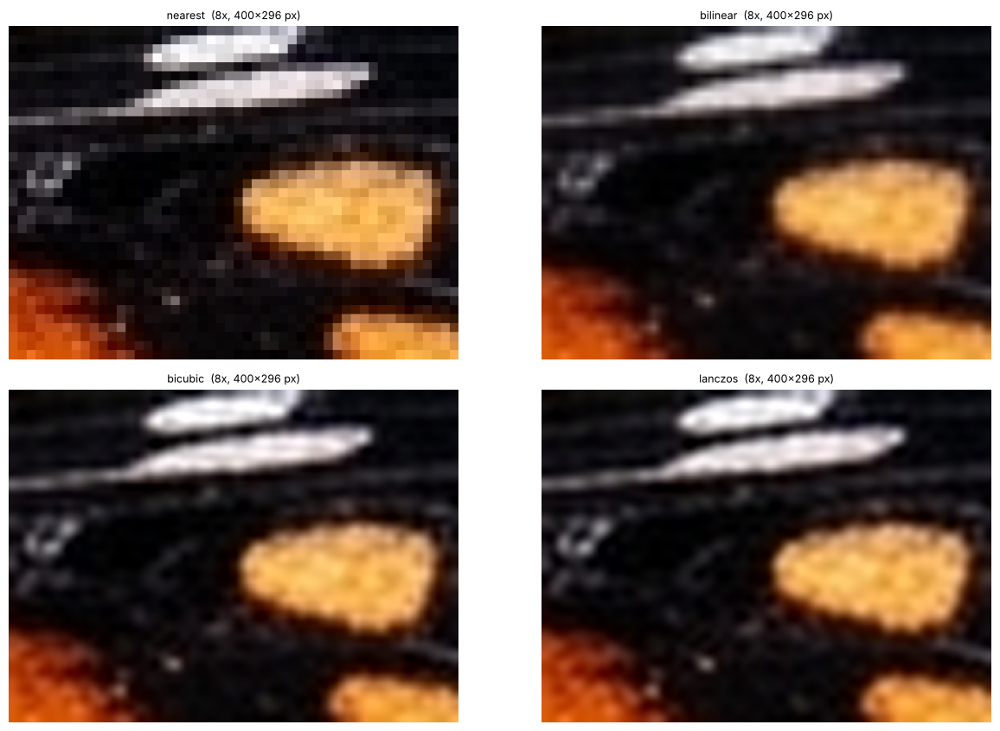

In [16]:
patch = transform(original, "crop", left=900, top=225, right=950, bottom=262)
print("Source patch:", patch.shape[1], "x", patch.shape[0], "px")

interp_items = []
for method in INTERPOLATIONS:
    big = transform(patch, "scale", sx=8, sy=8, interpolation=method)
    save_result(f"interp_patch_8x_{method}", big)
    interp_items.append((f"{method}  (8x, {big.shape[1]}x{big.shape[0]} px)", big))

show_gallery(interp_items, ncols=2, figwidth=13)

**Visible differences** (look at the edges of the white and orange spots)

| Method | What you see |
|---|---|
| **Nearest-neighbour** | Every source pixel becomes a hard 8x8 block - "staircase" edges and a mosaic look. No new colours are invented. |
| **Bilinear** | Smooth, no blocks, but edges are soft/blurred because each new pixel is an average of its 4 neighbours. |
| **Bicubic** | Smooth like bilinear but visibly crisper edges (it uses 16 neighbours); fine speckle texture in the orange spot is kept better than with bilinear. |
| **Lanczos** | Looks very close to bicubic on this patch, with edges marginally crisper (it uses an 8x8 neighbourhood). In general it is the method most likely to produce faint halos ("ringing") next to high-contrast edges, though they are hard to see here. |

For enlarging photographs, bicubic or Lanczos usually look best (bilinear is a faster, softer compromise); nearest-neighbour is only preferred when hard pixel edges must be kept (pixel art, label images).

## 7. Input validation - rejected inputs
Every case below is typed the way a user would type it (as **text**) and sent through `safe_run`, so you can see the exact error message.
There is at least one rejected input for **each operation**. For flipping an unsupported direction is used, and for rotation a
non-numeric and non-finite angle.

In [17]:
reject_cases = [
    # (operation, typed values)
    ("scale",     dict(sx="0",     sy="1",   interpolation="bilinear")),     # zero factor
    ("scale",     dict(sx="-2",    sy="1",   interpolation="bilinear")),     # negative factor
    ("scale",     dict(sx="abc",   sy="1",   interpolation="bilinear")),     # non-numeric
    ("scale",     dict(sx="1",     sy="nan", interpolation="bilinear")),     # NaN
    ("scale",     dict(sx="0.0001", sy="1",  interpolation="bilinear")),     # width would round to 0 px
    ("scale",     dict(sx="10",    sy="10",  interpolation="bicubic")),      # larger than the declared maximum
    ("scale",     dict(sx="2",     sy="2",   interpolation="cubic-spline")), # unsupported interpolation
    ("crop",      dict(left="500", top="100", right="400",  bottom="300")),  # left >= right
    ("crop",      dict(left="0",   top="0",   right="2000", bottom="500")),  # right > width
    ("crop",      dict(left="-5",  top="0",   right="100",  bottom="100")),  # negative coordinate
    ("crop",      dict(left="10.5", top="0",  right="100",  bottom="100")),  # not an integer
    ("flip",      dict(direction="diagonal")),                               # unsupported direction
    ("flip",      dict(direction="")),                                       # missing value
    ("translate", dict(tx="inf",  ty="0")),                                 # infinity
    ("translate", dict(tx="five", ty="0")),                                 # non-numeric
    ("rotate",    dict(angle="abc", expand="yes")),                         # non-numeric angle
    ("rotate",    dict(angle="nan", expand="yes")),                         # NaN angle
    ("rotate",    dict(angle="-inf", expand="no")),                         # non-finite angle
    ("rotate",    dict(angle="45", expand="maybe")),                        # invalid expansion choice
    ("shear",     dict(k="1")),                                             # unknown operation
    ("scale",     dict(sx="2", interpolation="bilinear")),                  # missing required parameter sy
]

rows = []
for op, raw in reject_cases:
    try:
        run_from_text(original, op, raw)
        outcome, message = "ACCEPTED (unexpected!)", ""
    except TransformError as err:
        outcome, message = "Rejected", str(err)
    rows.append({"Operation": op, "Typed input": ", ".join(f"{k}={v!r}" for k, v in raw.items()),
                 "Outcome": outcome, "Error message": message})
reject_df = pd.DataFrame(rows)
reject_df.index = reject_df.index + 1
display(reject_df)
assert (reject_df["Outcome"] == "Rejected").all()
print(f"All {len(reject_df)} invalid inputs were rejected with a message - no crash.")

,Operation,Typed input,Outcome,Error message
1,scale,"sx='0', sy='1', interpolation='bilinear'",Rejected,"Scale factors must be greater than zero, got sx=0.0, sy=1.0."
2,scale,"sx='-2', sy='1', interpolation='bilinear'",Rejected,"Scale factors must be greater than zero, got sx=-2.0, sy=1.0."
3,scale,"sx='abc', sy='1', interpolation='bilinear'",Rejected,"'sx' must be a number, but 'abc' is not numeric."
4,scale,"sx='1', sy='nan', interpolation='bilinear'",Rejected,"'sy' must be finite (NaN and infinity are not allowed), got nan."
5,scale,"sx='0.0001', sy='1', interpolation='bilinear'",Rejected,Output would be 0x768 px - an empty image is not allowed (minimum 1x1).
6,scale,"sx='10', sy='10', interpolation='bicubic'",Rejected,Output 14080x7680 px exceeds the maximum side length of 8000 px.
7,scale,"sx='2', sy='2', interpolation='cubic-spline'",Rejected,"Unsupported interpolation 'cubic-spline'. Choose one of: nearest, bilinear, bicubic, lanczos."
8,crop,"left='500', top='100', right='400', bottom='300'",Rejected,"Invalid horizontal range: need 0 <= left < right <= width (1408); got left=500, right=400."
9,crop,"left='0', top='0', right='2000', bottom='500'",Rejected,"Invalid horizontal range: need 0 <= left < right <= width (1408); got left=0, right=2000."
10,crop,"left='-5', top='0', right='100', bottom='100'",Rejected,"Invalid horizontal range: need 0 <= left < right <= width (1408); got left=-5, right=100."


All 21 invalid inputs were rejected with a message - no crash.


`transform` also validates **by itself** when it is called directly from code (not through the text prompts):

In [18]:
direct_cases = [
    ("image is None",                          lambda: transform(None, "flip", direction="both")),
    ("image has wrong dtype (float)",          lambda: transform(original.astype(float), "flip", direction="both")),
    ("operation is not a string",              lambda: transform(original, 5)),
    ("string passed as a number",              lambda: transform(original, "translate", tx="10", ty=0)),
    ("bool passed as a number",                lambda: transform(original, "rotate", angle=True, expand=False)),
    ("float passed as crop coordinate",        lambda: transform(original, "crop", left=0.5, top=0, right=10, bottom=10)),
    ("unexpected extra parameter",             lambda: transform(original, "flip", direction="both", angle=5)),
    ("expand given as text instead of bool",   lambda: transform(original, "rotate", angle=10, expand="yes")),
    ("rotation angle = numpy.nan",             lambda: transform(original, "rotate", angle=np.nan, expand=True)),
]
rows = []
for label, call in direct_cases:
    try:
        call()
        rows.append({"Direct call": label, "Outcome": "ACCEPTED (unexpected!)", "Error message": ""})
    except TransformError as err:
        rows.append({"Direct call": label, "Outcome": "Rejected", "Error message": str(err)})
display(pd.DataFrame(rows))

,Direct call,Outcome,Error message
0,image is None,Rejected,"image must be a NumPy array, got NoneType."
1,image has wrong dtype (float),Rejected,"image must be uint8, got float64."
2,operation is not a string,Rejected,operation must be a non-empty string.
3,string passed as a number,Rejected,"'tx' must be a number, got '10' (str)."
4,bool passed as a number,Rejected,"'angle' must be a number, got True (bool)."
5,float passed as crop coordinate,Rejected,"'left' must be an integer, got 0.5 (float)."
6,unexpected extra parameter,Rejected,Operation 'flip' got unexpected parameter(s): angle. Expected: direction.
7,expand given as text instead of bool,Rejected,"'expand' must be True or False, got 'yes' (str)."
8,rotation angle = numpy.nan,Rejected,"'angle' must be finite (NaN and infinity are not allowed), got nan."


**Valid boundary inputs must be accepted.** Zero, negative and exact-limit values that are legal are *not* rejected:

In [19]:
boundary_cases = [
    ("translate", dict(tx=0, ty=0),                                  "zero offsets"),
    ("translate", dict(tx=-300, ty=-120),                            "negative offsets"),
    ("translate", dict(tx=5000, ty=0),                               "offset larger than the image (everything clipped)"),
    ("rotate",    dict(angle=0, expand=False),                       "zero angle"),
    ("rotate",    dict(angle=-720.5, expand=True),                   "negative angle beyond a full turn"),
    ("crop",      dict(left=0, top=0, right=width, bottom=height),   "whole image (right = width, bottom = height)"),
    ("crop",      dict(left=width - 1, top=height - 1, right=width, bottom=height), "smallest crop: 1x1 px"),
    ("scale",     dict(sx=1 / width, sy=1 / height, interpolation="bilinear"),       "smallest valid scale: 1x1 px output"),
    ("scale",     dict(sx=MAX_OUTPUT_SIDE / width, sy=1, interpolation="nearest"),   "output width exactly at the maximum"),
]
rows = []
for op, params, why in boundary_cases:
    try:
        out = transform(original, op, **params)
        rows.append({"Operation": op, "Parameters": fmt_params(params) if len(fmt_params(params)) < 70 else "...",
                     "Case": why, "Outcome": "Accepted", "Output size": f"{out.shape[1]}x{out.shape[0]}"})
    except TransformError as err:
        rows.append({"Operation": op, "Parameters": fmt_params(params), "Case": why,
                     "Outcome": f"REJECTED: {err}", "Output size": ""})
display(pd.DataFrame(rows))

,Operation,Parameters,Case,Outcome,Output size
0,translate,"tx=0, ty=0",zero offsets,Accepted,1408x768
1,translate,"tx=-300, ty=-120",negative offsets,Accepted,1408x768
2,translate,"tx=5000, ty=0",offset larger than the image (everything clipped),Accepted,1408x768
3,rotate,"angle=0, expand=False",zero angle,Accepted,1408x768
4,rotate,"angle=-720.5, expand=True",negative angle beyond a full turn,Accepted,1415x781
5,crop,"left=0, top=0, right=1408, bottom=768","whole image (right = width, bottom = height)",Accepted,1408x768
6,crop,"left=1407, top=767, right=1408, bottom=768",smallest crop: 1x1 px,Accepted,1x1
7,scale,...,smallest valid scale: 1x1 px output,Accepted,1x1
8,scale,"sx=5.681818181818182, sy=1, interpolation=nearest",output width exactly at the maximum,Accepted,8000x768


## 8. Identity checks
With neutral parameters, the output must be **identical** to the original (same shape, zero pixel difference).

In [20]:
identity_cases = [
    ("scale 1.0 x 1.0, nearest",   "scale",     dict(sx=1.0, sy=1.0, interpolation="nearest")),
    ("scale 1.0 x 1.0, bilinear",  "scale",     dict(sx=1.0, sy=1.0, interpolation="bilinear")),
    ("scale 1.0 x 1.0, bicubic",   "scale",     dict(sx=1.0, sy=1.0, interpolation="bicubic")),
    ("scale 1.0 x 1.0, lanczos",   "scale",     dict(sx=1.0, sy=1.0, interpolation="lanczos")),
    ("translate tx=0, ty=0",       "translate", dict(tx=0, ty=0)),
    ("rotate 0 deg, expand=False", "rotate",    dict(angle=0, expand=False)),
    ("rotate 0 deg, expand=True",  "rotate",    dict(angle=0, expand=True)),
    ("rotate 360 deg, expand=False (full turn)", "rotate", dict(angle=360, expand=False)),
    ("crop of the whole image",    "crop",      dict(left=0, top=0, right=width, bottom=height)),
]
rows = []
for label, op, params in identity_cases:
    out = transform(original, op, **params)
    same_shape = out.shape == original.shape
    max_diff = int(np.abs(out.astype(int) - original.astype(int)).max()) if same_shape else -1
    passed = same_shape and max_diff == 0
    rows.append({"Check": label,
                 "Expected": f"shape {original.shape}, max pixel difference 0",
                 "Actual": f"shape {out.shape}, max pixel difference {max_diff}" if same_shape else f"shape {out.shape} (differs)",
                 "Result": "Pass" if passed else "Fail"})
identity_df = pd.DataFrame(rows)
identity_df.index = identity_df.index + 1
display(identity_df)
print("All identity checks passed." if (identity_df["Result"] == "Pass").all() else "SOME IDENTITY CHECKS FAILED")

,Check,Expected,Actual,Result
1,"scale 1.0 x 1.0, nearest","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
2,"scale 1.0 x 1.0, bilinear","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
3,"scale 1.0 x 1.0, bicubic","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
4,"scale 1.0 x 1.0, lanczos","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
5,"translate tx=0, ty=0","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
6,"rotate 0 deg, expand=False","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
7,"rotate 0 deg, expand=True","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
8,"rotate 360 deg, expand=False (full turn)","shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass
9,crop of the whole image,"shape (768, 1408, 3), max pixel difference 0","shape (768, 1408, 3), max pixel difference 0",Pass


All identity checks passed.


## 9. Concepts explained

### Image coordinates vs. array indexing
* **Image coordinates** are written **(x, y)**: `x` counts columns to the **right**, `y` counts rows **downward**, origin at the **top-left** pixel.
* A NumPy image is indexed **`image[row, column]` = `image[y, x]`** and its shape is **`(height, width, channels)`**.
  So the "(x, y)" you see on screen becomes `[y, x]` in code - the order flips.
* OpenCV functions take sizes and points in **(width, height)** / **(x, y)** order (e.g. `cv2.resize(img, (out_w, out_h))`) even though `img.shape` is `(h, w, c)`.
  That is why `transform` unpacks `h, w = image.shape[:2]` but passes `(w, h)` to OpenCV.
* Crop slicing `image[top:bottom, left:right]` therefore has rows first; `right` and `bottom` are exclusive like all Python slices.

In [21]:
x, y = 700, 300                       # a point: 700 px from the left, 300 px from the top
print("Pixel at (x=700, y=300):", original[y, x], "   <- written original[y, x] = original[300, 700]")
print("shape =", original.shape, "-> (height, width, channels);  OpenCV size argument is (width, height) =", (width, height))

Pixel at (x=700, y=300): [0 0 0]    <- written original[y, x] = original[300, 700]
shape = (768, 1408, 3) -> (height, width, channels);  OpenCV size argument is (width, height) = (1408, 768)


### Aspect-ratio distortion
The aspect ratio is `width / height` (1408 / 768 = 1.833). Scaling by `sx` and `sy` multiplies it by `sx / sy`. If the two factors are equal the picture is only
enlarged or reduced; if they differ the picture is **stretched or squashed** (section 5.1: 1.5 x 0.6 and 0.5 x 1.5).
To resize without distortion, use `sx == sy`.

### Rotation canvas expansion
A rotated rectangle needs more room than the original. For angle `theta` the smallest canvas that keeps every pixel is
`W' = w|cos(theta)| + h|sin(theta)|` and `H' = w|sin(theta)| + h|cos(theta)|` (rounded up). With `expand=False` the canvas stays `w x h` so the corners are cut off
and black triangles are exposed; with `expand=True` nothing is lost but the image gets bigger and gains black corner areas.

### Translation clipping
Translation keeps the canvas size. Pixels moved past an edge are **clipped (discarded)** and the strip on the opposite edge, with width `|tx|` and/or height `|ty|`,
has no source pixels so it is filled with **black**. Information that leaves the canvas is gone for good:

Round trip (+200,+80) then (-200,-80): 250,240 of 1,081,344 pixels differ (23.1 %)
-> exactly the pixels that were clipped the first time (right 200 columns and bottom 80 rows) are now black.


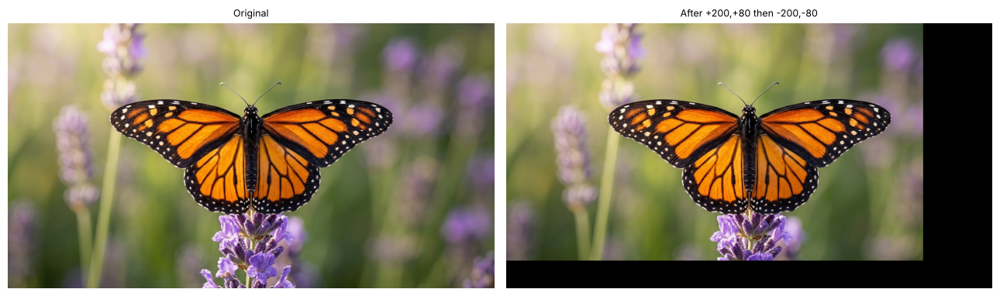

In [22]:
there = transform(original, "translate", tx=200, ty=80)
back  = transform(there,    "translate", tx=-200, ty=-80)       # try to undo the shift

differs = np.any(back != original, axis=2)
print(f"Round trip (+200,+80) then (-200,-80): {differs.sum():,} of {width*height:,} pixels differ ({100*differs.mean():.1f} %)")
print("-> exactly the pixels that were clipped the first time (right 200 columns and bottom 80 rows) are now black.")
show_gallery([("Original", original), ("After +200,+80 then -200,-80", back)], ncols=2, figwidth=13)

## 10. Final checks

In [23]:
unchanged = hashlib.sha256(original.tobytes()).hexdigest() == ORIGINAL_SHA256
print("Original image unchanged after all operations:", unchanged)
assert unchanged

saved_files = sorted(p.name for p in OUTPUT_DIR.glob("*.png"))
print(f"\n{len(saved_files)} transformed images saved in '{OUTPUT_DIR}/':")
for name in saved_files:
    print("  ", name)

Original image unchanged after all operations: True

25 transformed images saved in 'output/':
   crop_body_400_60_1000_520.png
   crop_topleft_0_0_704_384.png
   flip_both.png
   flip_horizontal.png
   flip_vertical.png
   interactive_1_scale.png
   interactive_2_crop.png
   interactive_3_rotate.png
   interactive_4_flip.png
   interactive_5_translate.png
   interp_patch_8x_bicubic.png
   interp_patch_8x_bilinear.png
   interp_patch_8x_lanczos.png
   interp_patch_8x_nearest.png
   rotate_+30_expand.png
   rotate_+30_noexpand.png
   rotate_-20_noexpand.png
   rotate_-45_expand.png
   rotate_90_expand.png
   scale_enlarge_2.0x2.0_bicubic.png
   scale_nonprop_0.5x1.5_bilinear.png
   scale_nonprop_1.5x0.6_lanczos.png
   scale_reduce_0.4x0.4_bilinear.png
   translate_tx+200_ty+80.png
   translate_tx-150_ty-60.png


## Conclusion
The single `transform` function performs scaling, cropping, flipping, translation and rotation with user-supplied values, validates the image, the operation name and every
parameter (including NaN / infinity, non-numeric text, invalid crop boxes, empty or oversized outputs), and returns clear error messages instead of crashing.
All identity checks passed, the original image was never modified, and all results were saved to `output/`.